# QAF-Net · NB1 — Site harmonization, cross-source duplicate audit, EDA
#
Runs **once**. Everything downstream reads this notebook's output.
#
**Accelerator: None (CPU). Internet: Off.** This is decode + hash work; a GPU here just burns quota.
#
**Attach these 5 DATASETS** (+ Add Input → filter to Datasets). Other people's notebooks are not datasets.
* `ashkhagan/figshare-brain-tumor-dataset`      → Site-A CHENG
* `orvile/brain-cancer-mri-dataset`             → Site-B PMRAM
* `sartajbhuvaji/brain-tumor-classification-mri`→ Site-C SARTAJ
* `ahmedhamada0/brain-tumor-detection`          → Site-D BR35H
* `masoudnickparvar/brain-tumor-mri-dataset`    → audit reference only
#
**Outputs** (NB2–NB4 attach this notebook's committed output directly):
`qafnet_data.npz`, `manifest.csv`, `dedup_report.json`, `eda_*.png`

In [1]:
SMOKE_TEST = False        # True → 200 files/site, a few minutes. COMMIT with False, never True.
STORE      = 144         # stored side length; models train at 128 with random crop
THUMB      = 64          # thumbnail size for the duplicate detector
DEDUP      = True        # False keeps cross-site near-duplicates (only for the C1 leakage ablation)
SEED       = 42
# The duplicate threshold TAU is CALIBRATED from the data in §3a — not set here. See the note
# there on why perceptual hashing fails on brain MRI.

import os, sys, io, json, glob, time, hashlib, random, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

random.seed(SEED); np.random.seed(SEED)
IN, OUT = "/kaggle/input", "/kaggle/working"
os.makedirs(OUT, exist_ok=True)

CLASSES = ["glioma", "meningioma", "pituitary", "notumor"]
C2I = {c: i for i, c in enumerate(CLASSES)}
TUMOR_SET = [0, 1, 2]                    # set-valued label for Br35H "yes"
print("classes:", CLASSES)

classes: ['glioma', 'meningioma', 'pituitary', 'notumor']


## 1. Locate the mounted datasets
Kaggle mount names occasionally differ from the slug, so resolve by searching rather than
hard-coding paths. If a site prints `MISSING`, you forgot to attach it.

In [2]:
# site: (dataset slug, title to search for on Kaggle, owner, labelled images in the current version)
SITES = {
    "CHENG":      ("figshare-brain-tumor-dataset",   "Figshare Brain Tumor Dataset",        "ashkhagan",        3064),
    "PMRAM":      ("brain-cancer-mri-dataset",       "Brain Cancer - MRI dataset",          "orvile",           6056),
    "SARTAJ":     ("brain-tumor-classification-mri", "Brain Tumor Classification (MRI)",    "sartajbhuvaji",    3264),
    "BR35H":      ("brain-tumor-detection",          "Br35H :: Brain Tumor Detection 2020", "ahmedhamada0",     3000),
    "NICKPARVAR": ("brain-tumor-mri-dataset",        "Brain Tumor MRI Dataset",             "masoudnickparvar", 7200),
}

def find_root(slug, max_depth=4):
    """Folder under /kaggle/input for a dataset slug: an exact name match first, then the shallowest
    folder whose name contains the slug.

    Exact-first matters because searching Kaggle for a dataset also lists other people's NOTEBOOKS,
    and an attached notebook mounts under its own name, e.g. 'brain-tumor-detection-br35h', which
    would otherwise pass for the 'brain-tumor-detection' dataset. The walk goes a few levels deep
    because Kaggle has changed where inputs mount before.
    """
    best = None
    base = IN.rstrip(os.sep).count(os.sep)
    for dirpath, dirnames, _ in os.walk(IN, followlinks=True):
        depth = dirpath.count(os.sep) - base
        if depth >= max_depth:
            dirnames[:] = []
            continue
        for d in dirnames:
            name = d.lower()
            if slug in name:
                cand = (name != slug, depth, os.path.join(dirpath, d))
                if best is None or cand < best:
                    best = cand
    return best[2] if best else None

ROOTS = {site: find_root(spec[0]) for site, spec in SITES.items()}
for site, root in ROOTS.items():
    print(f"{site:11s} {root or '*** MISSING ***'}")

CHENG       /kaggle/input/datasets/ashkhagan/figshare-brain-tumor-dataset
PMRAM       /kaggle/input/datasets/orvile/brain-cancer-mri-dataset
SARTAJ      /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri
BR35H       /kaggle/input/datasets/ahmedhamada0/brain-tumor-detection
NICKPARVAR  /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset


## 2. Loaders
#
CHENG ships MATLAB **v7.3** files, which are HDF5 — `scipy.io.loadmat` cannot read them, you need
`h5py`. MATLAB also stores arrays column-major, so the image comes out transposed.
#
**Label order is 1=meningioma, 2=glioma, 3=pituitary.** Getting 1 and 2 backwards is the single
easiest way to silently ruin this project, so we assert the published per-class counts below.

In [3]:
def to_u8(a):
    """Per-image min-max stretch to uint8. MRI arrives as int16/float with arbitrary range."""
    a = np.asarray(a, dtype=np.float32)
    lo, hi = float(a.min()), float(a.max())
    if hi - lo < 1e-8:
        return np.zeros(a.shape, np.uint8)
    return (((a - lo) / (hi - lo)) * 255.0).astype(np.uint8)

def resize_store(a_u8, size=STORE):
    return np.asarray(Image.fromarray(a_u8).resize((size, size), Image.BILINEAR), dtype=np.uint8)

def image_files(root):
    files = []
    for e in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff"):
        files += glob.glob(os.path.join(root, "**", e), recursive=True)
    return sorted(files)

def cheng_files(root):
    # cvind.mat ships beside the slices: it holds the authors' 5-fold CV indices, not an image.
    return [f for f in sorted(glob.glob(os.path.join(root, "**", "*.mat"), recursive=True))
            if os.path.basename(f).lower() != "cvind.mat"]

def load_cheng(root, limit=None):
    import h5py
    files = cheng_files(root)
    if limit: files = files[:: max(1, len(files) // limit)][:limit]
    print(f"  CHENG: {len(files)} .mat files")
    M2C = {1: "meningioma", 2: "glioma", 3: "pituitary"}    # <-- do not reorder
    rows = []
    for f in files:
        try:
            with h5py.File(f, "r") as h:
                g = h["cjdata"]
                lab = int(np.array(g["label"]).flatten()[0])
                pid = "".join(chr(int(c)) for c in np.array(g["PID"]).flatten())
                img = np.array(g["image"]).T                # MATLAB is column-major
        except Exception as e:
            print(f"    skip {os.path.basename(f)}: {e}"); continue
        rows.append(dict(site="CHENG", path=f, cls=M2C[lab], patient=pid.strip(),
                         img=resize_store(to_u8(img))))
    return rows

def norm_class(name):
    """Map a folder name from any source onto the unified label space."""
    n = name.lower().replace("_", "").replace("-", "").replace(" ", "")
    if "glioma" in n:                      return "glioma"
    if "menin" in n:                       return "meningioma"
    if "pituitary" in n:                   return "pituitary"
    if n in ("braintumor", "tumor"):       return "pituitary"   # PMRAM convention — VERIFY (§5)
    if "notumor" in n or "healthy" in n or n == "no":  return "notumor"
    if n == "yes":                         return "__TUMOR_ANY__"
    return None

def load_folder(root, site, limit=None):
    files = image_files(root)
    # Stride across the sorted list so a smoke test sees every class folder, not only the
    # alphabetically first one (for Br35H that is Br35H-Mask-RCNN/, which maps to no class).
    if limit: files = files[:: max(1, len(files) // limit)][:limit]
    print(f"  {site}: {len(files)} image files")
    rows, unmapped = [], set()
    for f in files:
        cls = None
        for part in reversed(os.path.normpath(f).split(os.sep)[:-1]):
            cls = norm_class(part)
            if cls: break
        if cls is None:
            unmapped.add(os.path.basename(os.path.dirname(f))); continue
        try:
            im = Image.open(f).convert("L")
        except Exception:
            continue
        rows.append(dict(site=site, path=f, cls=cls, patient="",
                         img=resize_store(np.asarray(im, np.uint8))))
    if unmapped:
        print(f"    unmapped folders (ignored): {sorted(unmapped)[:8]}")
    return rows

### 2b. Are these the right datasets?
#
Searching Kaggle for a dataset also lists other people's **notebooks**, and attaching a notebook
mounts that notebook's output files, not the images. Same-named copies under other owners exist
too. This counts the labelled files in each site folder and stops, with instructions, if a dataset
is missing, empty, or clearly the wrong thing.

In [4]:
problems, check = [], []
print(f"{'site':11s} {'status':7s} {'labelled':>8s} {'expected':>8s}  folder")
for site, (slug, title, owner, want) in SITES.items():
    root = ROOTS[site]
    if root is None:
        n, status = 0, "MISSING"
    else:
        if site == "CHENG":
            n = len(cheng_files(root))
        else:
            n = sum(1 for f in image_files(root)
                    if any(norm_class(p) for p in os.path.normpath(f).split(os.sep)[:-1]))
        if n == 0:
            status = "EMPTY"
        elif abs(n - want) <= 0.1 * want:
            status = "ok"
        elif os.path.basename(root).lower() == slug:
            status = "CHECK"     # right folder name, different size: maybe a newer dataset version
        else:
            status = "WRONG"     # wrong size AND wrong name: almost certainly a notebook or a copy
    if status in ("MISSING", "EMPTY", "WRONG"):
        problems.append(f"   {site:10s} search Datasets for '{title}' and add the one by '{owner}'")
    elif status == "CHECK":
        check.append(site)
    print(f"{site:11s} {status:7s} {n:8d} {want:8d}  {root or '-'}")

if check:
    print()
    print(f"CHECK {check}: size differs from the current published version. Confirm the owner in the Input panel.")
if problems:
    print()
    print("Attached under /kaggle/input:", sorted(os.listdir(IN)) if os.path.isdir(IN) else "nothing")
    print("Fix these in the Input panel (under DATASETS, not NOTEBOOKS), then Run All again:")
    for line in problems:
        print(line)
    raise RuntimeError("Not all five datasets are attached - see the list printed above.")
print("All five datasets found.")

site        status  labelled expected  folder
CHENG       ok          3064     3064  /kaggle/input/datasets/ashkhagan/figshare-brain-tumor-dataset
PMRAM       ok          6056     6056  /kaggle/input/datasets/orvile/brain-cancer-mri-dataset
SARTAJ      ok          3264     3264  /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri
BR35H       ok          3000     3000  /kaggle/input/datasets/ahmedhamada0/brain-tumor-detection
NICKPARVAR  ok          7200     7200  /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
All five datasets found.


In [5]:
LIMIT = 200 if SMOKE_TEST else None
t0 = time.time()
records = []
if ROOTS["CHENG"]:  records += load_cheng(ROOTS["CHENG"], LIMIT)
for site in ["PMRAM", "SARTAJ", "BR35H", "NICKPARVAR"]:
    if ROOTS[site]: records += load_folder(ROOTS[site], site, LIMIT)
print(f"\nloaded {len(records)} images in {time.time()-t0:.0f}s")

df = pd.DataFrame([{k: v for k, v in r.items() if k != "img"} for r in records])
IMGS = np.stack([r["img"] for r in records]).astype(np.uint8)
print(IMGS.shape, IMGS.dtype)
print(pd.crosstab(df.site, df.cls))

  CHENG: 3064 .mat files
  PMRAM: 6056 image files
  SARTAJ: 3264 image files
  BR35H: 3861 image files
    unmapped folders (ignored): ['TEST', 'TRAIN', 'VAL', 'pred']
  NICKPARVAR: 7200 image files

loaded 22584 images in 403s
(22584, 144, 144) uint8
cls         __TUMOR_ANY__  glioma  meningioma  notumor  pituitary
site                                                             
BR35H                1500       0           0     1500          0
CHENG                   0    1426         708        0        930
NICKPARVAR              0    1800        1800     1800       1800
PMRAM                   0    2004        2004        0       2048
SARTAJ                  0     926         937      500        901


### Label sanity check
Published CHENG counts: meningioma **708**, glioma **1426**, pituitary **930**.
If this assertion fires on a full run, the label map is wrong — fix it, don't delete the check.

In [6]:
if not SMOKE_TEST and (df.site == "CHENG").any():
    got = df[df.site == "CHENG"].cls.value_counts().to_dict()
    exp = {"meningioma": 708, "glioma": 1426, "pituitary": 930}
    print("CHENG counts:", got, "| expected:", exp)
    assert got == exp, "CHENG label mapping is wrong — check M2C (1=meningioma, 2=glioma)"
    print("label mapping verified")

CHENG counts: {'glioma': 1426, 'pituitary': 930, 'meningioma': 708} | expected: {'meningioma': 708, 'glioma': 1426, 'pituitary': 930}
label mapping verified


## 3. Cross-source duplicate audit  ← contribution C1
#
`masoudnickparvar` is a *merge* of CHENG + SARTAJ + BR35H, and SARTAJ is itself partly
re-derived from CHENG. If you train on one and test on another without removing the overlap,
your "cross-dataset" number is partly measuring memorisation.
#
### Why not a perceptual hash
#
The obvious tool is dHash/pHash. **It does not work here.** Every brain MRI slice is the same
global picture — a bright oval on a black field — so a 64-bit difference hash puts *independent
patients* within a few bits of each other. Tested on synthetic data with known ground truth,
64-bit dHash at Hamming ≤ 5 flagged **~78% of genuinely independent images as duplicates**. It
would have silently deleted most of the legitimate data and produced a nonsense overlap table.
#
Instead: **normalized cross-correlation (NCC) on mean-subtracted 64×64 thumbnails**, which is one
BLAS matmul and separates cleanly. Plus MD5 over the stored pixels for exact copies.
#
The threshold is **calibrated below against the observed distribution**, not hard-coded — the
separation point depends on how self-similar the real data turns out to be, and we report a
sensitivity analysis over it.

In [7]:
def ncc_vecs(imgs, s=THUMB):
    """Mean-subtracted, L2-normalised thumbnails. V @ V.T is then a correlation matrix."""
    V = np.zeros((len(imgs), s * s), np.float32)
    for i, a in enumerate(imgs):
        v = np.asarray(Image.fromarray(a).resize((s, s), Image.BILINEAR), np.float32).ravel()
        v -= v.mean()
        V[i] = v / (np.linalg.norm(v) + 1e-8)
    return V

def max_corr(A, B, chunk=1024, exclude_self=False):
    """For each row of A, the best correlation against any row of B, and which one."""
    best = np.full(len(A), -1.0, np.float32); arg = np.zeros(len(A), np.int64)
    for i in range(0, len(A), chunk):
        C = A[i:i+chunk] @ B.T
        if exclude_self:
            for r in range(len(C)):
                if i + r < C.shape[1]:
                    C[r, i + r] = -1.0
        best[i:i+len(C)] = C.max(1); arg[i:i+len(C)] = C.argmax(1)
    return best, arg

t0 = time.time()
V   = ncc_vecs(IMGS)
md5 = np.array([hashlib.md5(a.tobytes()).hexdigest() for a in IMGS])
df["md5"] = md5
print(f"built NCC vectors for {len(V)} images in {time.time()-t0:.0f}s  (dim={V.shape[1]})")

sites  = [s for s in ["CHENG", "PMRAM", "SARTAJ", "BR35H", "NICKPARVAR"] if (df.site == s).any()]
idx_of = {s: np.where(df.site.values == s)[0] for s in sites}

built NCC vectors for 22584 images in 6s  (dim=4096)


### 3a. Calibrate the threshold — do not skip this
#
`PMRAM` was independently acquired in Bangladesh and shares no provenance with `CHENG` (China),
so **CHENG↔PMRAM is our negative control**: whatever correlation those reach is what
"different patient, different scanner" looks like. A valid threshold must sit above it.

negative control (CHENG vs PMRAM — no shared provenance):
    p50    = 0.68851
    p90    = 0.80126
    p99    = 0.86727
    p99.9  = 0.89423
    p100   = 0.91099

  -> any threshold must exceed 0.89423 or it deletes independent images

TAU = 0.999

SARTAJ images with NCC >= 0.999 against CHENG: 71.8%


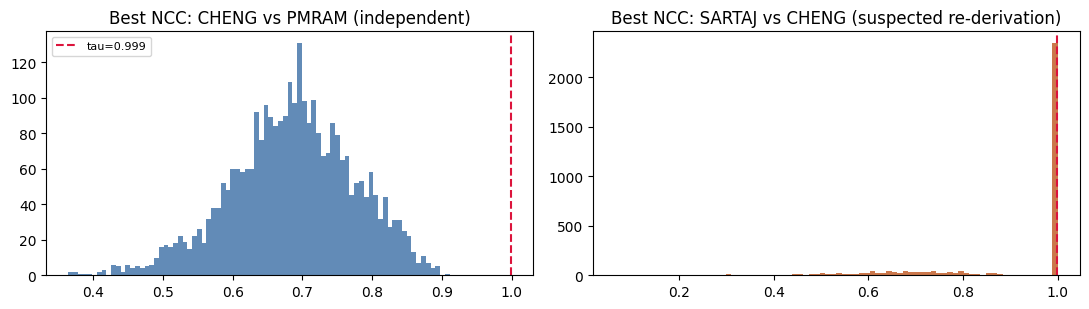

In [8]:
if "CHENG" in idx_of and "PMRAM" in idx_of:
    ctrl, _ = max_corr(V[idx_of["CHENG"]], V[idx_of["PMRAM"]])
    print("negative control (CHENG vs PMRAM — no shared provenance):")
    for p in [50, 90, 99, 99.9, 100]:
        print(f"    p{p:<5} = {np.percentile(ctrl, p):.5f}")
    floor = float(np.percentile(ctrl, 99.9))
    print(f"\n  -> any threshold must exceed {floor:.5f} or it deletes independent images")
else:
    ctrl, floor = None, 0.995

TAU = max(0.999, round(floor + 0.0005, 4)) if DEDUP else 2.0   # NCC <= 1, so 2.0 disables dedup
print(f"\nTAU = {TAU}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
if ctrl is not None:
    ax[0].hist(ctrl, bins=80, color="#3b6ea5", alpha=.8)
    ax[0].axvline(TAU, c="crimson", ls="--", lw=1.5, label=f"tau={TAU}")
    ax[0].set_title("Best NCC: CHENG vs PMRAM (independent)"); ax[0].legend(fontsize=8)
if "SARTAJ" in idx_of and "CHENG" in idx_of:
    susp, _ = max_corr(V[idx_of["SARTAJ"]], V[idx_of["CHENG"]])
    ax[1].hist(susp, bins=80, color="#c0561f", alpha=.8)
    ax[1].axvline(TAU, c="crimson", ls="--", lw=1.5)
    ax[1].set_title("Best NCC: SARTAJ vs CHENG (suspected re-derivation)")
    print(f"\nSARTAJ images with NCC >= {TAU} against CHENG: "
          f"{100*(susp >= TAU).mean():.1f}%")
plt.tight_layout(); plt.savefig(f"{OUT}/eda_dedup_calibration.png", dpi=140); plt.show()

### 3b. Eyeball the flagged pairs
The strongest cross-site matches, side by side. If these are visibly the *same slice*, the
threshold is right. If they are different patients that merely look alike, raise `TAU`.

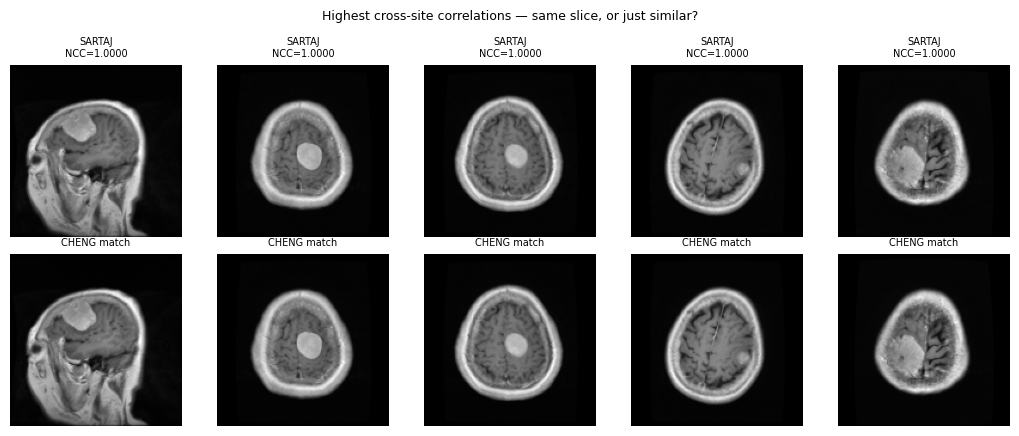

In [9]:
if "SARTAJ" in idx_of and "CHENG" in idx_of:
    b, a_idx = max_corr(V[idx_of["SARTAJ"]], V[idx_of["CHENG"]])
    top = np.argsort(-b)[:5]
    fig, ax = plt.subplots(2, len(top), figsize=(2.1*len(top), 4.4))
    for c, t in enumerate(top):
        ax[0, c].imshow(IMGS[idx_of["SARTAJ"][t]], cmap="gray"); ax[0, c].axis("off")
        ax[0, c].set_title(f"SARTAJ\nNCC={b[t]:.4f}", fontsize=7)
        ax[1, c].imshow(IMGS[idx_of["CHENG"][a_idx[t]]], cmap="gray"); ax[1, c].axis("off")
        ax[1, c].set_title("CHENG match", fontsize=7)
    plt.suptitle("Highest cross-site correlations — same slice, or just similar?", fontsize=9)
    plt.tight_layout(); plt.savefig(f"{OUT}/eda_dup_pairs.png", dpi=140); plt.show()

### 3c. Overlap matrix (paper table) + threshold sensitivity

In [10]:
overlap = pd.DataFrame(0.0, index=sites, columns=sites)
for a in sites:
    for b_ in sites:
        best, _ = max_corr(V[idx_of[a]], V[idx_of[b_]], exclude_self=(a == b_))
        overlap.loc[a, b_] = 100.0 * (best >= TAU).mean()

print(f"% of ROW site's images with a near-duplicate in COLUMN site (NCC >= {TAU}):")
print(overlap.round(1).to_string())

sens = {}
for t in [0.99, 0.995, 0.999, 0.9995, 0.9999]:
    row = {}
    for a in sites:
        if a == "NICKPARVAR":
            continue
        others = [s for s in sites if s not in (a, "NICKPARVAR")]
        if not others:
            continue
        best, _ = max_corr(V[idx_of[a]], np.concatenate([V[idx_of[o]] for o in others]))
        row[a] = round(100.0 * (best >= t).mean(), 1)
    sens[t] = row
print(f"\nsensitivity — % flagged as duplicate at each threshold:")
print(pd.DataFrame(sens).T.to_string())

% of ROW site's images with a near-duplicate in COLUMN site (NCC >= 0.999):
            CHENG  PMRAM  SARTAJ  BR35H  NICKPARVAR
CHENG         0.0    0.0    74.8    0.1        57.4
PMRAM         0.0    1.3     0.0    0.0         0.0
SARTAJ       71.8    0.0    22.2   11.8        82.9
BR35H         0.1    0.0    12.3   45.5        52.7
NICKPARVAR   24.8    0.0    38.6   23.8        23.0

sensitivity — % flagged as duplicate at each threshold:
        CHENG  PMRAM  SARTAJ  BR35H
0.9900   74.8    0.0    83.9   14.9
0.9950   74.8    0.0    83.7   14.2
0.9990   74.8    0.0    83.5   12.3
0.9995   74.8    0.0    83.5   12.0
0.9999   51.4    0.0    61.1    9.9


### Build the deduplicated federation
#
Three rules, applied site by site in priority order **CHENG → PMRAM → SARTAJ → BR35H**
(CHENG is the upstream source with patient IDs; PMRAM was acquired independently):
#
1. **exact copy in site**: identical pixels inside one site. Keep the first.
2. **copy of X**: a near-duplicate of an image already kept at a higher-priority site X. Drop it here.
3. **near copy in site**: near-duplicates inside one site. Keep the first. If the twins carry
   *different labels*, drop both (**label conflict in site**): there is no way to know which is right.
#
Twins inside a site matter even though LOSO holds whole sites out: without this rule one copy can
land in training and the other in validation, which inflates validation accuracy.
#
The table shows how many images each rule removed. It also reports how often a cross-site copy's
label disagrees with its source, a direct measure of label noise in the derived datasets.
`NICKPARVAR` is audit-only and never becomes a client.

In [11]:
PRIORITY = ["CHENG", "PMRAM", "SARTAJ", "BR35H"]
keep = np.ones(len(df), bool)
keep[df.site.values == "NICKPARVAR"] = False        # audit reference, not a client
reason = np.full(len(df), "", dtype=object)          # why each dropped image was dropped
cls_arr = df.cls.values
label_mismatch = {}                                  # "SITE<-SOURCE": [copies found, labels disagreeing]

def same_label(a, b):
    """Labels agree, treating Br35H's unspecified tumour as compatible with any tumour class."""
    return a == b or ("__TUMOR_ANY__" in (a, b) and "notumor" not in (a, b))

def drop(idx, why):
    idx = np.asarray(idx, dtype=np.int64)
    reason[idx[reason[idx] == ""]] = why             # the first reason found is the one reported
    keep[idx] = False

for i, site in enumerate(PRIORITY):
    if site not in idx_of: continue
    mine = idx_of[site]
    # (1) exact copies inside the site: keep the first
    _, first = np.unique(df.md5.values[mine], return_index=True)
    drop(mine[np.setdiff1d(np.arange(len(mine)), first)], "exact copy in site")
    # (2) near-duplicates of a higher-priority site: the higher-priority copy wins
    for hp in PRIORITY[:i]:
        if hp not in idx_of: continue
        ref = idx_of[hp][keep[idx_of[hp]]]
        if len(ref) == 0: continue
        best, arg = max_corr(V[mine], V[ref])
        hit = best >= TAU
        if hit.any():
            agree = [same_label(cls_arr[m], cls_arr[r]) for m, r in zip(mine[hit], ref[arg[hit]])]
            label_mismatch[f"{site}<-{hp}"] = [int(hit.sum()), int(len(agree) - sum(agree))]
        drop(mine[hit], f"copy of {hp}")
    # (3) near-duplicates inside the site: keep the first of each group; twins whose labels
    #     disagree are BOTH dropped
    Vm = V[mine]
    near = np.zeros(len(mine), bool)
    conflict = np.zeros(len(mine), bool)
    for s0 in range(0, len(mine), 1024):
        C = Vm[s0:s0 + 1024] @ Vm.T
        for r in range(len(C)):
            C[r, s0 + r:] = -1.0                     # compare only with EARLIER images
        best, arg = C.max(1), C.argmax(1)
        for r in np.where(best >= TAU)[0]:
            a, b = s0 + r, int(arg[r])
            near[a] = True
            if not same_label(cls_arr[mine[a]], cls_arr[mine[b]]):
                conflict[a] = conflict[b] = True
    drop(mine[conflict], "label conflict in site")
    drop(mine[near & ~conflict], "near copy in site")

df["keep"], df["drop_reason"] = keep, reason
clients = df[df.site != "NICKPARVAR"]
survival = clients.groupby("site").agg(total=("keep", "size"), kept=("keep", "sum"))
survival["survival_%"] = (100 * survival.kept / survival.total).round(1)
gone = clients[clients.drop_reason != ""]
reasons = pd.crosstab(gone.site, gone.drop_reason) if len(gone) else pd.DataFrame(index=survival.index)
drop_reasons = {s: {k: int(v) for k, v in row.items() if v} for s, row in reasons.iterrows()}
print(survival.join(reasons).fillna(0).astype({c: int for c in reasons.columns}).to_string())

if label_mismatch:
    print()
    print("Cross-site copies whose label DISAGREES with the higher-priority copy (label noise):")
    for k, (found, bad) in label_mismatch.items():
        print(f"   {k:16s} {bad} of {found} copies ({100 * bad / found:.1f}%)")

print()
print("Kept images by site and class (the primary experiment uses glioma / meningioma / pituitary):")
print(pd.crosstab(clients[clients.keep].site, clients[clients.keep].cls).to_string())

# A site losing most of its images is either a real finding (it was mostly copied from another
# site) or a threshold that is too low. The pair figure in 3b tells you which.
for s, r in survival.iterrows():
    if r["survival_%"] < 50:
        print(f"  !! {s} lost {100 - r['survival_%']:.0f}% of its images. If the 3b pairs are the same slices, "
              f"this is real and part of the C1 finding; if they are different patients, TAU is too low.")
    if r["kept"] < 300:
        print(f"  !! {s} has only {int(r['kept'])} images left, too few to be a federated client. "
              f"See the fallback in docs/01-research-design.md section 3.")

# NICKPARVAR audit: how much of the standard benchmark is re-used from its constituent sources?
if "NICKPARVAR" in idx_of:
    src = np.concatenate([idx_of[s] for s in ["CHENG", "SARTAJ", "BR35H"] if s in idx_of])
    best, _ = max_corr(V[idx_of["NICKPARVAR"]], V[src])
    nick_dup = 100.0 * (best >= TAU).mean()
    print(f"\nAUDIT: {nick_dup:.1f}% of masoudnickparvar images have a near-duplicate "
          f"in {{CHENG, SARTAJ, BR35H}} — it is a merge, not an independent set.")
else:
    nick_dup = None

        total  kept  survival_%  copy of CHENG  copy of SARTAJ  exact copy in site  label conflict in site  near copy in site
site                                                                                                                         
BR35H    3000  1908        63.6              2             362                   1                       0                727
CHENG    3064  3064       100.0              0               0                   0                       0                  0
PMRAM    6056  6012        99.3              0               0                  44                       0                  0
SARTAJ   3264   544        16.7           2291               0                 394                       4                 31

Cross-site copies whose label DISAGREES with the higher-priority copy (label noise):
   SARTAJ<-CHENG    14 of 2345 copies (0.6%)
   BR35H<-CHENG     0 of 2 copies (0.0%)
   BR35H<-SARTAJ    0 of 362 copies (0.0%)

Kept images by site and clas

## 4. Patient-wise grouping
#
CHENG has real patient IDs, so its splits are grouped by patient — adjacent slices of one tumour
must never straddle train and test. The other sources ship no patient information; each image
becomes its own group and we state that as a limitation in the paper.

In [12]:
df["group"] = np.where(df.patient.astype(str).str.len() > 0,
                       df.site + "_P" + df.patient.astype(str),
                       df.site + "_I" + df.index.astype(str))
print("groups per site:")
print(df[df.keep].groupby("site").group.nunique().to_string())

# Set-valued labels: singleton for normal classes, {glioma,meningioma,pituitary} for Br35H "yes".
def label_set(c):
    return TUMOR_SET if c == "__TUMOR_ANY__" else [C2I[c]]
df["label"]     = df.cls.map(lambda c: -1 if c == "__TUMOR_ANY__" else C2I[c])
df["label_set"] = df.cls.map(lambda c: ",".join(map(str, label_set(c))))
df["partial"]   = (df.label == -1).astype(int)

groups per site:
site
BR35H     1908
CHENG      233
PMRAM     6012
SARTAJ     544


## 5. EDA — and the PMRAM label check you must do by eye
#
Compare the PMRAM `brain_tumor` row against the CHENG `pituitary` row. They should be the same
kind of thing: a small, central, bright, contrast-enhancing sellar mass. If PMRAM's row looks
nothing like it, the `brain_tumor → pituitary` mapping in `norm_class()` is wrong.

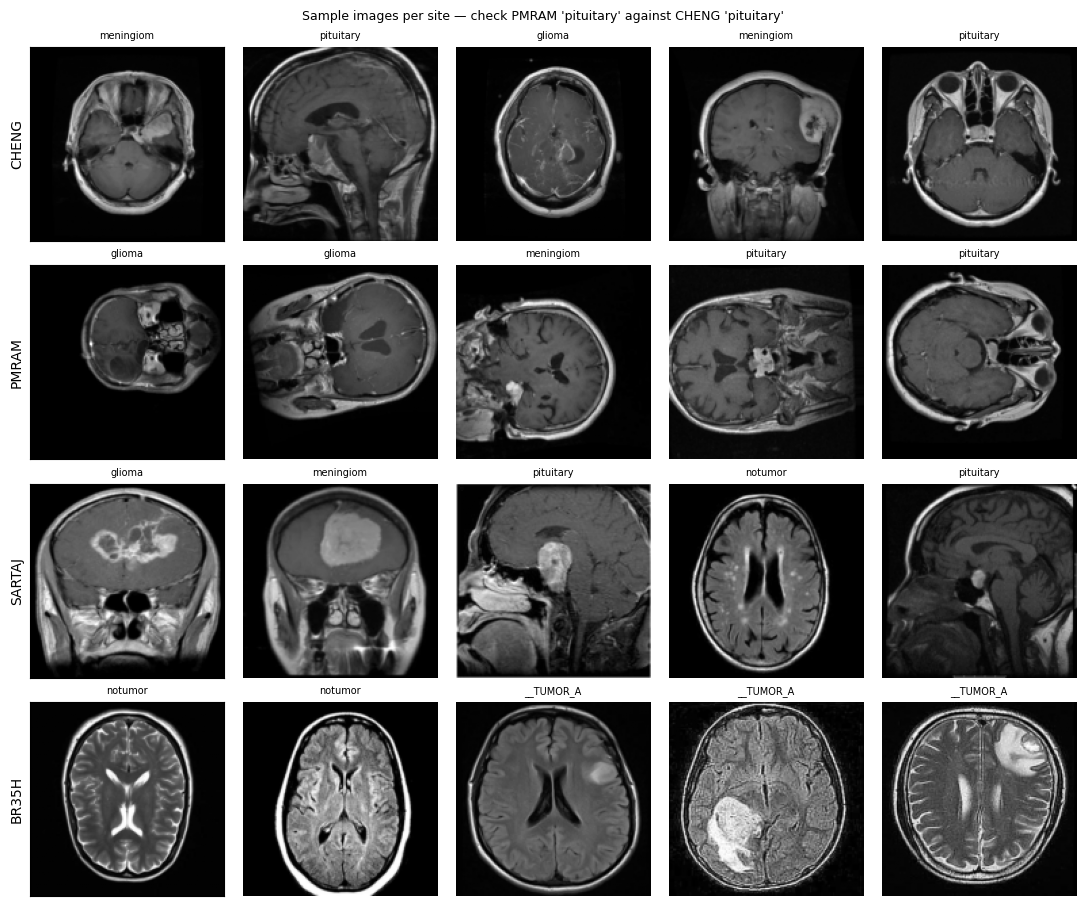

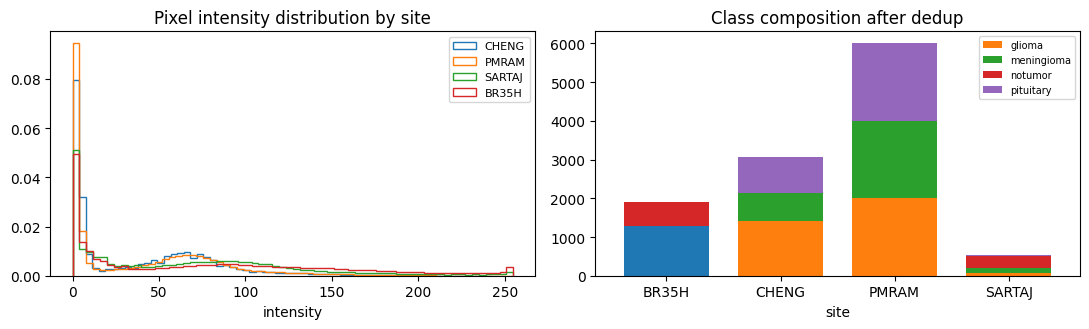

In [13]:
d = df[df.keep]
fig, axes = plt.subplots(len(sites) - (1 if "NICKPARVAR" in sites else 0), 5,
                         figsize=(11, 2.3 * (len(sites) - 1)))
axes = np.atleast_2d(axes)
r = 0
for s in sites:
    if s == "NICKPARVAR": continue
    sub = d[d.site == s]
    for c in range(5):
        ax = axes[r, c]; ax.axis("off")
        if c < len(sub):
            k = sub.index[np.linspace(0, len(sub) - 1, 5).astype(int)[c]]
            ax.imshow(IMGS[k], cmap="gray")
            ax.set_title(f"{df.cls[k][:9]}", fontsize=7)
    axes[r, 0].set_ylabel(s); axes[r, 0].axis("on")
    axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    r += 1
plt.suptitle("Sample images per site — check PMRAM 'pituitary' against CHENG 'pituitary'", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/eda_samples.png", dpi=140); plt.show()

# Intensity profiles: this is the domain shift, made visible. It is a paper figure.
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for s in [x for x in sites if x != "NICKPARVAR"]:
    v = IMGS[d.index[d.site == s]].reshape(-1)[::97]
    ax[0].hist(v, bins=64, density=True, histtype="step", lw=1.6, label=s)
ax[0].set_title("Pixel intensity distribution by site"); ax[0].set_xlabel("intensity"); ax[0].legend(fontsize=8)
ct = pd.crosstab(d.site, d.cls)
ct.plot(kind="bar", stacked=True, ax=ax[1], width=.75)
ax[1].set_title("Class composition after dedup"); ax[1].tick_params(axis="x", rotation=0)
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/eda_shift.png", dpi=140); plt.show()

## 6. Save
`qafnet_data.npz` + `manifest.csv` are what NB2/NB3/NB4 consume.

In [14]:
kept = np.where(df.keep.values)[0]
np.savez_compressed(f"{OUT}/qafnet_data.npz",
                    images=IMGS[kept],
                    labels=df.label.values[kept].astype(np.int16),
                    partial=df.partial.values[kept].astype(np.int8),
                    site=df.site.values[kept].astype("U12"),
                    group=df.group.values[kept].astype("U40"),
                    classes=np.array(CLASSES), store=np.array([STORE]),
                    smoke_test=np.array([SMOKE_TEST]), dedup=np.array([DEDUP]))

df.loc[kept, ["site", "path", "cls", "label", "label_set", "partial", "patient", "group", "md5"]] \
  .to_csv(f"{OUT}/manifest.csv", index=False)

report = dict(
    smoke_test=SMOKE_TEST, store=STORE, thumb=THUMB, tau=TAU,
    tau_sensitivity={str(k): v for k, v in sens.items()},
    n_loaded=int(len(df)), n_kept=int(len(kept)),
    overlap_pct=overlap.round(2).to_dict(),
    survival=survival.to_dict(),
    drop_reasons=drop_reasons,
    label_mismatch=label_mismatch,
    kept_by_site_class=pd.crosstab(d.site, d.cls).to_dict(),
    dedup=DEDUP,
    nickparvar_dup_pct=nick_dup,
    class_counts=d.cls.value_counts().to_dict(),
    site_counts=d.site.value_counts().to_dict(),
)
json.dump(report, open(f"{OUT}/dedup_report.json", "w"), indent=2, default=str)
print(json.dumps(report, indent=2, default=str))

{
  "smoke_test": false,
  "store": 144,
  "thumb": 64,
  "tau": 0.999,
  "tau_sensitivity": {
    "0.99": {
      "CHENG": 74.8,
      "PMRAM": 0.0,
      "SARTAJ": 83.9,
      "BR35H": 14.9
    },
    "0.995": {
      "CHENG": 74.8,
      "PMRAM": 0.0,
      "SARTAJ": 83.7,
      "BR35H": 14.2
    },
    "0.999": {
      "CHENG": 74.8,
      "PMRAM": 0.0,
      "SARTAJ": 83.5,
      "BR35H": 12.3
    },
    "0.9995": {
      "CHENG": 74.8,
      "PMRAM": 0.0,
      "SARTAJ": 83.5,
      "BR35H": 12.0
    },
    "0.9999": {
      "CHENG": 51.4,
      "PMRAM": 0.0,
      "SARTAJ": 61.1,
      "BR35H": 9.9
    }
  },
  "n_loaded": 22584,
  "n_kept": 11528,
  "overlap_pct": {
    "CHENG": {
      "CHENG": 0.0,
      "PMRAM": 0.0,
      "SARTAJ": 71.84,
      "BR35H": 0.07,
      "NICKPARVAR": 24.85
    },
    "PMRAM": {
      "CHENG": 0.0,
      "PMRAM": 1.32,
      "SARTAJ": 0.0,
      "BR35H": 0.0,
      "NICKPARVAR": 0.0
    },
    "SARTAJ": {
      "CHENG": 74.77,
      "PMRAM": 0.0,

---
### Next
1. Re-run with `SMOKE_TEST = False`, then **Save Version → Save & Run All (Commit)**.
2. In NB2/NB3/NB4: **+ Add Input** → search `qafnet nb1` → pick it under **Notebooks** → Add.
   That mounts this notebook's committed output directly; there is no dataset to create.
3. Never upload the raw MRI files. They are already on Kaggle, and they are not what NB2–NB4 read.
#
Record from `dedup_report.json` for the paper: the overlap matrix, per-site survival rates, and
the NICKPARVAR duplication percentage.